# TP3 — Gestion des Valeurs Manquantes

Corrigé intégral : exploration initiale, questions 1 à 13 et sous-questions 2.1 à 2.3. Les résultats des différentes imputations ne constituent pas une évaluation de leur précision : celle-ci nécessiterait de masquer des âges connus et de mesurer les erreurs sur un jeu réservé.

Source : [Titanic, Data Science Dojo](https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv). Le fichier local est chargé en priorité. Les noms de colonnes du CSV sont conservés. Chaque traitement repart des données originales.

In [2]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import zscore
import missingno as msno
from sklearn.linear_model import LinearRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import IsolationForest
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.dpi': 110})
pd.set_option('display.max_rows', 100)
URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
chemin = Path('titanic.csv')
df_original = pd.read_csv(chemin if chemin.exists() else URL)
df = df_original.copy(deep=True)
def bilan(avant, apres, colonnes=('Age',)):
    display(pd.DataFrame({'Avant': avant[list(colonnes)].isna().sum(),
                          'Après': apres[list(colonnes)].isna().sum()}))
def interpretation(texte):
    display(Markdown('**Interprétation des résultats calculés.** ' + texte))


## Question Exploration 1

In [ ]:
display(df.head())
display(df.dtypes.to_frame("Type"))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,Type
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


### Interprétation

Chaque ligne représente un passager ; PassengerId est un identifiant et Survived la cible de survie.

## Question Exploration 2

In [ ]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 891
Nombre de colonnes : 12


### Interprétation

Le fichier contient 891 passagers et 12 variables.

## Question Exploration 3

In [ ]:
display(df.isna().sum().to_frame("Valeurs manquantes"))
print("Total :", df.isna().sum().sum())

,Valeurs manquantes
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Total : 866


### Interprétation

Age contient 177 absences, Cabin 687 et Embarked 2, soit 866 cellules manquantes.

## Question 1

In [ ]:
display((100*df.isna().mean()).round(2).to_frame("Pourcentage manquant"))

,Pourcentage manquant
PassengerId,0.00
Survived,0.00
Pclass,0.00
Name,0.00
Sex,0.00
Age,19.87
SibSp,0.00
Parch,0.00
Ticket,0.00
Fare,0.00


### Interprétation

Cabin est absente pour environ 77 % des passagers ; supprimer toutes les lignes incomplètes serait très coûteux.

## Question 2

In [ ]:
print("Colonnes concernées :", df.columns[df.isna().any()].tolist())

Colonnes concernées : ['Age', 'Cabin', 'Embarked']


### Interprétation

Les colonnes concernées sont Age, Cabin et Embarked.

## Question 2.1

In [ ]:
display(df.isnull().sum().to_frame("Nombre manquant"))

,Nombre manquant
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


### Interprétation

Les autres colonnes ne présentent aucune valeur manquante dans ce fichier.

## Question 2.2

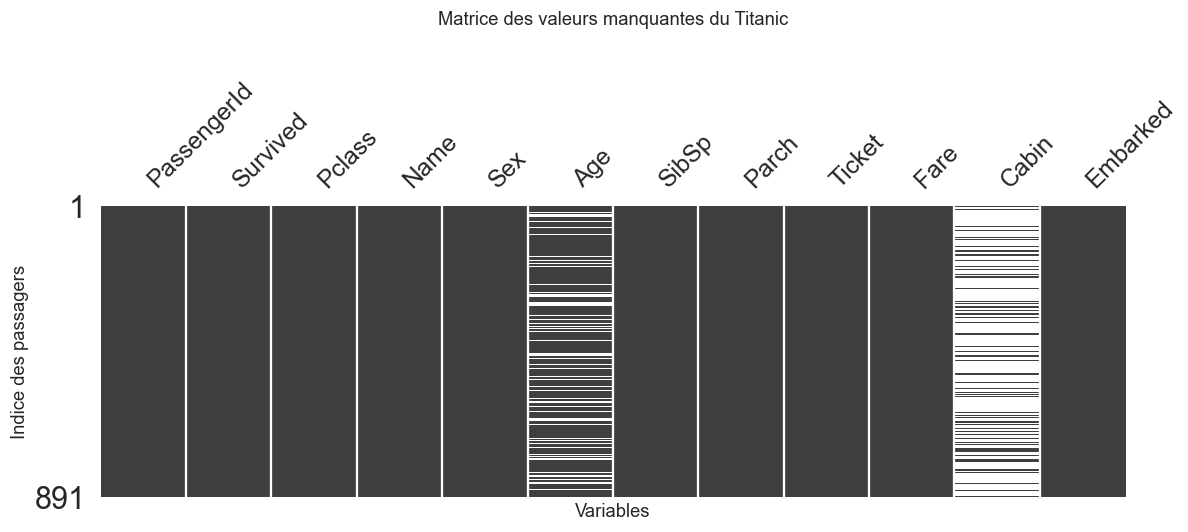

In [ ]:
ax = msno.matrix(df, figsize=(11, 5), sparkline=False)
ax.set_title("Matrice des valeurs manquantes du Titanic", pad=35)
ax.set_xlabel("Variables")
ax.set_ylabel("Indice des passagers")
plt.tight_layout()
plt.show()

### Interprétation

Les espaces blancs sont particulièrement nombreux dans Cabin ; Age présente également de nombreuses interruptions.

## Question 2.3

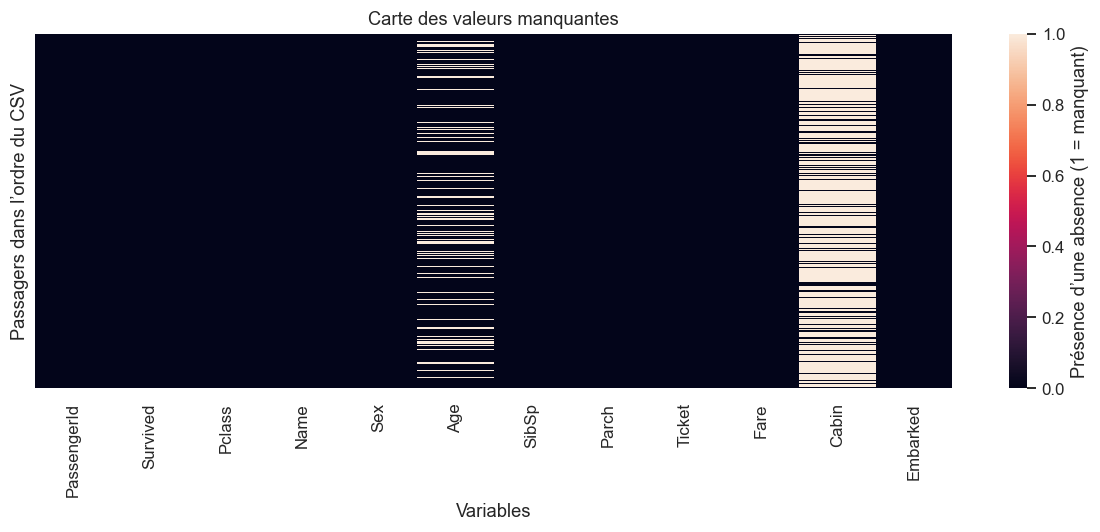

In [ ]:
plt.figure(figsize=(11,5))
ax = sns.heatmap(df.isna().astype(int), cbar_kws={"label":"Présence d’une absence (1 = manquant)"}, yticklabels=False)
ax.set(title="Carte des valeurs manquantes", xlabel="Variables", ylabel="Passagers dans l’ordre du CSV")
plt.tight_layout()
plt.show()

### Interprétation

La carte confirme que les absences sont concentrées dans trois colonnes, principalement Cabin.

## Question 3

In [ ]:
df_sans_lignes = df.copy().dropna(axis=0)
print("Dimensions après suppression :", df_sans_lignes.shape)
print("Lignes supprimées :", len(df)-len(df_sans_lignes))

Dimensions après suppression : (183, 12)
Lignes supprimées : 708


### Interprétation

Il reste 183 lignes et 12 colonnes ; 708 passagers sont exclus, principalement à cause de Cabin.

## Question 4

In [ ]:
print(f"Part conservée : {len(df_sans_lignes)/len(df):.2%}")
display(pd.DataFrame({"Original (%)": df.Pclass.value_counts(normalize=True)*100, "Cas complets (%)": df_sans_lignes.Pclass.value_counts(normalize=True)*100}).sort_index().round(2))

Part conservée : 20.54%


,Original (%),Cas complets (%)
Pclass,,
1,24.24,86.34
2,20.65,8.20
3,55.11,5.46


### Interprétation

Environ 20,54 % des lignes sont conservées. La répartition des classes change : les cas complets ne sont pas représentatifs de l’ensemble.

## Question 5

In [ ]:
df_sans_embarked = df.copy().dropna(subset=["Embarked"])
print("Dimensions :", df_sans_embarked.shape)

Dimensions : (889, 12)


### Interprétation

Deux lignes sont retirées ; il reste 889 lignes et 12 colonnes. Les absences dans Age et Cabin restent présentes.

## Question 6

In [ ]:
df_sans_cabin = df.copy().drop(columns=["Cabin"])
print("Dimensions :", df_sans_cabin.shape)
print(f"Cabin manquante : {df.Cabin.isna().mean():.2%}")

Dimensions : (891, 11)
Cabin manquante : 77.10%


### Interprétation

La suppression de Cabin conserve 891 lignes et laisse 11 colonnes.

## Question 7

In [ ]:
df_moyenne = df.copy()
df_mediane = df.copy()
df_mode = df.copy()
df_moyenne["Age"] = df.Age.fillna(df.Age.mean())
df_mediane["Age"] = df.Age.fillna(df.Age.median())
df_mode["Age"] = df.Age.fillna(df.Age.mode().iloc[0])
for copie in [df_moyenne, df_mediane, df_mode]:
    copie["Embarked"] = df.Embarked.fillna(df.Embarked.mode().iloc[0])
display(pd.Series({"Moyenne Age":df.Age.mean(),"Médiane Age":df.Age.median(),"Mode Age":df.Age.mode().iloc[0],"Mode Embarked":df.Embarked.mode().iloc[0]},name="Valeur utilisée"))
bilan(df, df_mediane, ["Age","Embarked"])

Moyenne Age      29.699118
Médiane Age           28.0
Mode Age              24.0
Mode Embarked            S
Name: Valeur utilisée, dtype: object

,Avant,Après
Age,177,0
Embarked,2,0


### Interprétation

La moyenne d’Age vaut environ 29,70 ans, la médiane 28 et le mode 24 ; le port modal est S. Les 177 âges et les 2 ports sont remplis dans chaque copie, tandis que Cabin reste incomplète. L’imputation simple réduit artificiellement la variabilité.

## Question 8

In [ ]:
df_avant = df.copy(); df_arriere = df.copy()
df_avant["Age"] = df.Age.ffill()
df_arriere["Age"] = df.Age.bfill()
bilan(df, df_avant); bilan(df, df_arriere)
display(pd.DataFrame({"Original":df.Age,"Avant":df_avant.Age,"Arrière":df_arriere.Age}).head(12))

,Avant,Après
Age,177,0


,Avant,Après
Age,177,0


,Original,Avant,Arrière
0,22.0,22.0,22.0
1,38.0,38.0,38.0
2,26.0,26.0,26.0
3,35.0,35.0,35.0
4,35.0,35.0,35.0
5,NaN,35.0,54.0
6,54.0,54.0,54.0
7,2.0,2.0,2.0
8,27.0,27.0,27.0
9,14.0,14.0,14.0


### Interprétation

Les deux méthodes remplissent ici les 177 absences car les premières et dernières valeurs sont connues. Elles dépendent de l’ordre du CSV et peuvent attribuer l’âge d’un passager sans lien avec le suivant.

## Question 9 — Appliquer l’interpolation pour la colonne Age.

In [ ]:
df_interpolation = df.copy()
df_interpolation["Age"] = df.Age.interpolate(method="linear")
bilan(df, df_interpolation)
display(pd.DataFrame({"Original":df.Age,"Interpolation":df_interpolation.Age}).head(12))

,Avant,Après
Age,177,0


,Original,Interpolation
0,22.0,22.0
1,38.0,38.0
2,26.0,26.0
3,35.0,35.0
4,35.0,35.0
5,NaN,44.5
6,54.0,54.0
7,2.0,2.0
8,27.0,27.0
9,14.0,14.0


### Interprétation

Les 177 absences sont comblées ici. Le résultat illustre la méthode mais n’établit pas la plausibilité des âges estimés.

## Question 10

In [ ]:
variables = ["Pclass", "SibSp", "Parch", "Fare"]
connus = df.Age.notna()
regression = LinearRegression().fit(df.loc[connus, variables], df.loc[connus,"Age"])
df_regression = df.copy()
df_regression.loc[~connus,"Age"] = regression.predict(df.loc[~connus, variables])
bilan(df, df_regression)
display(pd.Series(regression.coef_,index=variables,name="Coefficient"))
display(df_regression.loc[~connus, variables+["Age"]].head(10))
interpretation(f"Les 177 âges sont estimés ; leur plage est [{df_regression.loc[~connus,'Age'].min():.2f} ; {df_regression.loc[~connus,'Age'].max():.2f}] ans.")

,Avant,Après
Age,177,0


Pclass   -6.776636
SibSp    -3.827720
Parch    -1.195094
Fare     -0.019862
Name: Coefficient, dtype: float64

,Pclass,SibSp,Parch,Fare,Age
5,3,0,0,8.4583,27.525206
17,2,0,0,13.0000,34.211637
19,3,0,0,7.2250,27.549701
26,3,0,0,7.2250,27.549701
28,3,0,0,7.8792,27.536708
29,3,0,0,7.8958,27.536378
31,1,1,0,146.5208,34.508625
32,3,0,0,7.7500,27.539274
36,3,0,0,7.2292,27.549618
42,3,0,0,7.8958,27.536378


**Interprétation des résultats calculés.** Les 177 âges sont estimés ; leur plage est [-6.70 ; 41.25] ans.

### Interprétation

Les coefficients décrivent des associations conditionnelles, sans prouver un lien causal. Aucun score de précision n’est déduit de la seule disparition des absences.

## Question 11

In [ ]:
colonnes = ["Age"] + variables
jeux_multiples = []
for graine in range(42,47):
    imputation = IterativeImputer(random_state=graine, sample_posterior=True, max_iter=20, min_value=0)
    copie = df.copy()
    valeurs = imputation.fit_transform(df[colonnes])
    copie.loc[~connus,"Age"] = valeurs[~connus,0]
    jeux_multiples.append(copie)
bilan(df, jeux_multiples[0])
comparaison_multiple = pd.DataFrame({f"Jeu {i+1}": d.loc[~connus,"Age"] for i,d in enumerate(jeux_multiples)})
display(comparaison_multiple.head(10))
display(comparaison_multiple.agg(["mean","min","max"]))
interpretation(f"Les cinq jeux sont complets pour Age. L’écart-type moyen entre imputations d’un même âge absent vaut {comparaison_multiple.std(axis=1).mean():.2f} ans.")

,Avant,Après
Age,177,0


,Jeu 1,Jeu 2,Jeu 3,Jeu 4,Jeu 5
5,28.504483,52.447318,10.878660,21.216205,25.786203
17,37.690044,50.894132,24.513883,24.632857,40.304139
19,19.204249,30.387676,56.718017,57.074871,30.739960
26,8.805103,38.306499,31.577062,43.214585,50.086618
28,24.378474,9.671301,37.812163,43.482273,17.590522
29,18.747339,51.088901,26.478657,10.886123,16.984230
31,24.577077,18.217374,8.600046,14.286762,51.147158
32,50.435089,33.902188,30.475694,23.998695,22.675968
36,31.695799,22.464804,22.270925,33.451234,21.936456
42,29.727271,29.096152,18.291476,31.258571,36.432533


,Jeu 1,Jeu 2,Jeu 3,Jeu 4,Jeu 5
mean,28.285057,29.671346,28.285250,29.367731,29.039054
min,0.000000,0.000000,0.000000,0.000000,0.000000
max,71.347809,57.858480,62.417902,62.612351,65.609427


**Interprétation des résultats calculés.** Les cinq jeux sont complets pour Age. L’écart-type moyen entre imputations d’un même âge absent vaut 10.69 ans.

### Interprétation

Les imputations diffèrent d’un jeu à l’autre ; remplacer ces cinq jeux par une seule moyenne ferait perdre l’incertitude. Les tirages positifs ne garantissent pas tous des âges biologiquement plausibles et doivent être contrôlés avant une analyse réelle.

## Question 12 — Appliquer pour la colonne Age.

In [ ]:
standardisation = StandardScaler()
standardisees = standardisation.fit_transform(df[colonnes])
imputeur_knn = KNNImputer(n_neighbors=5, weights="distance")
reconstituees = standardisation.inverse_transform(imputeur_knn.fit_transform(standardisees))
df_knn = df.copy()
df_knn.loc[~connus,"Age"] = reconstituees[~connus,0]
bilan(df, df_knn)
display(df_knn.loc[~connus, colonnes].head(10))
interpretation(f"L’âge moyen imputé par KNN vaut {df_knn.loc[~connus,'Age'].mean():.2f} ans.")

,Avant,Après
Age,177,0


,Age,Pclass,SibSp,Parch,Fare
5,24.013921,3,0,0,8.4583
17,30.600000,2,0,0,13.0000
19,29.500000,3,0,0,7.2250
26,29.500000,3,0,0,7.2250
28,19.002349,3,0,0,7.8792
29,29.800000,3,0,0,7.8958
31,27.496067,1,1,0,146.5208
32,47.800000,3,0,0,7.7500
36,21.166667,3,0,0,7.2292
42,29.800000,3,0,0,7.8958


**Interprétation des résultats calculés.** L’âge moyen imputé par KNN vaut 31.49 ans.

### Interprétation

Les 177 âges absents sont remplacés par des moyennes pondérées d’âges voisins ; le résultat dépend de k, des variables et de la distance choisie.

\## Question 13

In [ ]:
arbre = DecisionTreeRegressor(min_samples_leaf=10, random_state=42)
arbre.fit(df.loc[connus, variables], df.loc[connus,"Age"])
df_arbre = df.copy()
df_arbre.loc[~connus,"Age"] = arbre.predict(df.loc[~connus,variables])
bilan(df, df_arbre)
display(df_arbre.loc[~connus, colonnes].head(10))
methodes = {"Moyenne":df_moyenne,"Médiane":df_mediane,"Mode":df_mode,"Forward Fill":df_avant,"Backward Fill":df_arriere,"Interpolation":df_interpolation,"Régression":df_regression,"Itérative (jeu 1)":jeux_multiples[0],"KNN":df_knn,"Arbre":df_arbre}
display(pd.DataFrame({nom:{"Absences avant":int(df.Age.isna().sum()),"Absences après":int(d.Age.isna().sum()),"Moyenne des âges imputés":d.loc[~connus,"Age"].mean()} for nom,d in methodes.items()}).T.round(3))
for d in methodes.values():
    assert d.loc[connus,"Age"].equals(df.loc[connus,"Age"])
pd.testing.assert_frame_equal(df, df_original)

,Avant,Après
Age,177,0


,Age,Pclass,SibSp,Parch,Fare
5,25.440000,3,0,0,8.4583
17,32.051020,2,0,0,13.0000
19,29.576923,3,0,0,7.2250
26,29.576923,3,0,0,7.2250
28,24.681818,3,0,0,7.8792
29,27.913043,3,0,0,7.8958
31,30.846154,1,1,0,146.5208
32,35.250000,3,0,0,7.7500
36,26.718750,3,0,0,7.2292
42,27.913043,3,0,0,7.8958


,Absences avant,Absences après,Moyenne des âges imputés
Moyenne,177.0,0.0,29.699
Médiane,177.0,0.0,28.000
Mode,177.0,0.0,24.000
Forward Fill,177.0,0.0,29.107
Backward Fill,177.0,0.0,30.562
Interpolation,177.0,0.0,29.835
Régression,177.0,0.0,27.593
Itérative (jeu 1),177.0,0.0,28.285
KNN,177.0,0.0,31.494
Arbre,177.0,0.0,29.617


### Interprétation

Les méthodes complètent toutes Age sans modifier les âges connus ni les données originales. Les différences de moyenne ne permettent pas de choisir la meilleure méthode ; une validation sur des âges connus masqués est nécessaire.